# Exercise 5 — 20 telescopes, 10 m equivalent, 30 m equivalent

*Covers notebooks 04. Difficulty: ★★★★☆*

The headline sensitivity curves against the array size, for both instruments.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 10, "legend.fontsize": 8})

# the array sizes compared throughout: replicated in arrays of 20, one spectrograph input per array
SCALES = {20: "nominal 20x (3.2 m eq.)", 200: "10 arrays (10.3 m eq.)", 1720: "86 arrays (30.1 m eq.)"}
NS = np.array([20, 40, 60, 100, 200, 400, 600, 1000, 1720, 2500])

def tel(n, telescopes_per_input=20):
    return Telescope(n_telescopes=int(n), fiber="18um", combine="fiber", telescopes_per_input=telescopes_per_input)

def mark_scales(ax):
    for n in (20, 200, 1720):
        ax.axvline(n, color="0.6", ls="--", lw=0.8)
    ax.set_xscale("log"); ax.set_xlabel("Number of telescopes")
    equivalent_diameter_axis(ax, ticks=(3, 5, 10, 20, 30))

LFAST is replicated in arrays of 20 unit telescopes. The nominal Kitt Peak array (20 x 0.726 m,
8.3 m$^2$) has the collecting area of a 3.2 m telescope; 10 arrays (200 telescopes) match a
10.3 m aperture and 86 arrays (1720 telescopes) a 30.1 m aperture. This exercise builds the
scaling model and produces the headline sensitivity curves against the array size.

How arrays combine in the ETC: each 20-to-1 fiber combiner feeds one spectrograph input. Within an
array, star and sky electrons both scale with the number of telescopes while detector noise is
incurred once; beyond 20, one input per array, co-added incoherently, so the SNR grows as
$\sqrt{n_{arrays}}$ on top of the single-array value. An idealised single combiner
(`telescopes_per_input=None`) is shown dotted where it matters.

This is a photon-budget scaling and nothing more: it assumes the spectrographs scale with the
arrays, that the per-array throughput stays at the Choi et al. (2026) values, and that sky
subtraction and fiber-combiner stability do not limit faint-end performance. Multiplexing is not
modelled.

In [2]:
# the array sizes compared throughout: replicated in arrays of 20, one spectrograph input per array
SCALES = {20: "nominal 20x (3.2 m eq.)", 200: "10 arrays (10.3 m eq.)", 1720: "86 arrays (30.1 m eq.)"}
NS = np.array([20, 40, 60, 100, 200, 400, 600, 1000, 1720, 2500])

def tel(n, telescopes_per_input=20):
    return Telescope(n_telescopes=int(n), fiber="18um", combine="fiber", telescopes_per_input=telescopes_per_input)

def mark_scales(ax):
    for n in (20, 200, 1720):
        ax.axvline(n, color="0.6", ls="--", lw=0.8)
    ax.set_xscale("log"); ax.set_xlabel("Number of telescopes")
    equivalent_diameter_axis(ax, ticks=(3, 5, 10, 20, 30))

### 5.1 — Equivalent apertures

A table of arrays, collecting area, equivalent diameter and number of spectrograph inputs for every
N in `NS`.

In [3]:
apertures = pd.DataFrame(
    {int(n): {"Arrays": -(-int(n) // 20), "Area (m2)": tel(int(n)).total_area_m2,
              "D_eq (m)": tel(int(n)).equivalent_diameter_m, "Spectrographs": tel(int(n)).n_inputs}
     for n in NS}).T.rename_axis("N telescopes")
apertures.astype({"Arrays": int, "Spectrographs": int}).round(1)

,Arrays,Area (m2),D_eq (m),Spectrographs
N telescopes,,,,
20,1,8.3,3.2,1
40,2,16.6,4.6,2
60,3,24.8,5.6,3
100,5,41.4,7.3,5
200,10,82.8,10.3,10
400,20,165.6,14.5,20
600,30,248.4,17.8,30
1000,50,414.0,23.0,50
1720,86,712.0,30.1,86


### 5.2 — Limiting magnitude versus array size, both instruments

Three cases: the Bench in V over 500 to 650 nm, CSHELL at R = 18k in H for one setting at 1.555 um,
and CSHELL at R = 43k in J at the He 10830 line. Plot the SNR 10 limiting magnitude against N for
60, 900 and 3600 s, solid for one combiner per 20 telescopes and dotted for the idealised single
combiner. Where is the gap between them largest, and why?

> ✏️ **Before you run the next cell:** which instrument gains more from a single combiner feeding all 1720 telescopes into one spectrograph: the Bench or CSHELL? Write your guess down (or put it in the room poll), then run.

N=20  N=200  N=1720  \
case (SNR=10 per resel)                  exposure (s)                         
Bench R~1800, V, 500-650 nm              60            16.32  17.96   19.25   
                                         900           18.85  20.32   21.55   
                                         3600          19.85  21.22   22.43   
CSHELL R=18k, H, one setting at 1.555 um 60             8.92  10.20   11.38   
                                         900           11.55  12.82   13.99   
                                         3600          12.58  13.84   15.01   
CSHELL R=43k, J, He 10830                60             8.33   9.63   10.81   
                                         900           10.97  12.25   13.42   
                                         3600          12.00  13.27   14.45   

                                                       gain 20->200  \
case (SNR=10 per resel)                  exposure (s)                 
Bench R~1800, V, 500-650 nm              60                    1.64   
                                         900                   1.47   
                                         3600                  1.37   
CSHELL R=18k, H, one setting at 1.555 um 60                    1.28   
                                         900                   1.27   
                                         3600                  1.26   
CSHELL R=43k, J, He 10830                60                    1.29   
                                         900                   1.28   
                                         3600                  1.27   

                                                       gain 20->1720  
case (SNR=10 per resel)                  exposure (s)                 
Bench R~1800, V, 500-650 nm              60                     2.93  
                                         900                    2.70  
                                         3600                   2.58  
CSHELL R=18k, H, one setting at 1.555 um 60                     2.45  
                                         900                    2.44  
                                         3600                   2.43  
CSHELL R=43k, J, He 10830                60                     2.47  
                                         900                    2.46  
                                         3600                   2.44

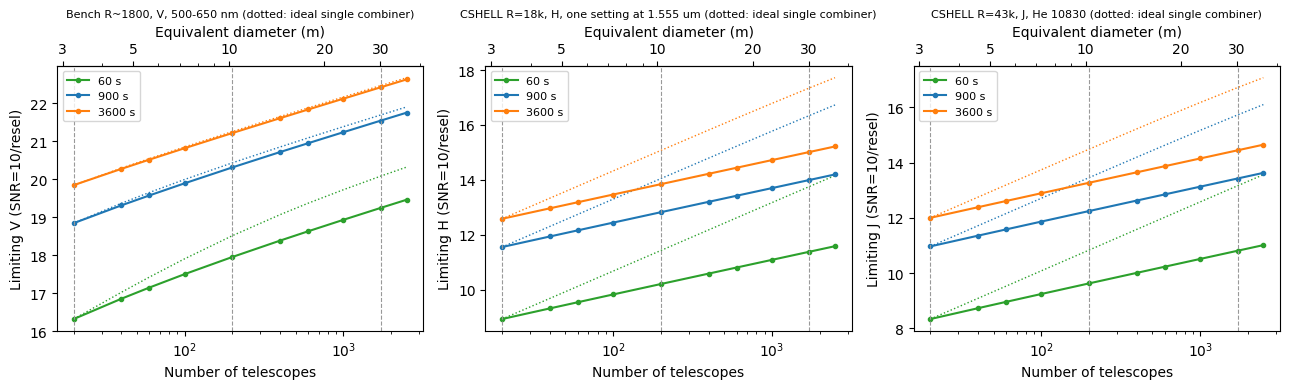

In [4]:
gstar = Source.blackbody(5800, 0, "V")
kstar = Source.blackbody(4500, 0, "H")
cs_lo, cs_hi = Instrument.from_preset("cshell_r18000").setting_window(1555.0)
cases = {
    "Bench R~1800, V, 500-650 nm": ("bench_r1800", gstar, dict(), (500, 650)),
    "CSHELL R=18k, H, one setting at 1.555 um": ("cshell_r18000", kstar, dict(wavelength_min_nm=cs_lo, wavelength_max_nm=cs_hi), None),
    "CSHELL R=43k, J, He 10830": ("cshell_r43000", Source.blackbody(4800, 0, "J"), dict(wavelength_min_nm=1081, wavelength_max_nm=1086), 1083.3),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
summary = {}
for ax, (label, (preset, src, kw, win)) in zip(axes, cases.items()):
    for exp, color in ((60, "C2"), (900, "C0"), (3600, "C1")):
        lim = [LFASTETC(preset, telescope=tel(int(n)), **kw).limiting_magnitude(src, exp, 10, wavelength=win) for n in NS]
        ideal = [LFASTETC(preset, telescope=tel(int(n), telescopes_per_input=None), **kw).limiting_magnitude(src, exp, 10, wavelength=win) for n in NS]
        ax.plot(NS, lim, marker="o", ms=3, color=color, label=f"{exp} s")
        ax.plot(NS, ideal, ls=":", color=color, lw=1)
        summary[(label, exp)] = dict(zip(NS, lim))
    ax.set_ylabel(f"Limiting {src.band} (SNR=10/resel)")
    ax.set_title(label + " (dotted: ideal single combiner)", fontsize=8); ax.legend()
    mark_scales(ax)
plt.tight_layout()
lim_table = pd.DataFrame({(label, exp): {f"N={n}": d[n] for n in SCALES} for (label, exp), d in summary.items()}).T
lim_table.index.names = ["case (SNR=10 per resel)", "exposure (s)"]
lim_table["gain 20->200"] = lim_table["N=200"] - lim_table["N=20"]
lim_table["gain 20->1720"] = lim_table["N=1720"] - lim_table["N=20"]
lim_table.astype(float).round(2)
# The gap is largest for CSHELL: a single combiner would pay its noisy detector once instead of
# once per array (~1.2 mag deeper at 200 and ~2.3 mag at 1720 in 15 min). For the Bench it is ~0.1 mag.

### 5.3 — The regimes

At fixed SNR the required exposure time scales as $1/N$ in every regime once the array count grows
(incoherent co-add of inputs), and faster than $1/N$ inside a single array when detector noise
matters. Plot the exposure time relative to the 20-telescope value against N for a G star at V = 12,
18 and 21, with the $1/N$ line. Which regime is each magnitude in?

Text(0.5, 1.0, 'Bench, SNR=10 per resel, 5800 K')

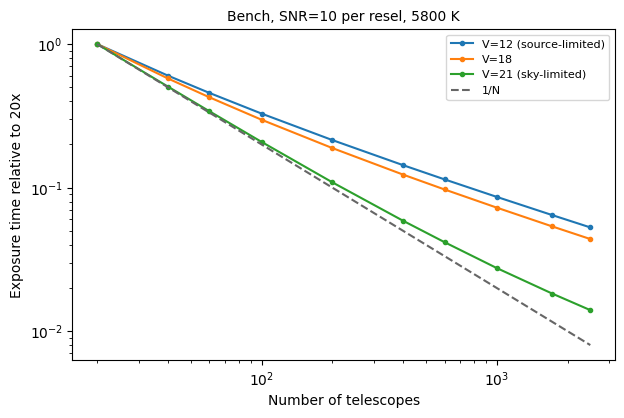

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.3))
for mag, label in ((12, "V=12 (source-limited)"), (18, "V=18"), (21, "V=21 (sky-limited)")):
    t = [LFASTETC("bench_r1800", telescope=tel(int(n))).exptime_vs_mag(gstar, [mag], snr=10, wavelength=(500, 650))[0] for n in NS]
    ax.plot(NS, np.array(t) / t[0], marker="o", ms=3, label=label)
ax.plot(NS, 20 / NS, color="0.4", ls="--", label="1/N")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Number of telescopes"); ax.set_ylabel("Exposure time relative to 20x")
ax.legend(); ax.set_title("Bench, SNR=10 per resel, 5800 K")
# The magnitude gain at fixed time is 2.5 log10(N) when source limited and 1.25 log10(N) when
# background limited, so the faint-end gain from 20 to 1720 telescopes is between 2.4 and 4.8 mag.

### 5.4 — Classification depth versus array size

Using the classification metric of exercise 2 (SNR 5 per R = 300 bin over 450 to 650 nm, a
10,000 K SED in R), plot the depth against N for 5, 30 and 60 minutes, with the Argus single-epoch
(g = 20.0), Argus 15-minute co-add (g = 21.5) and LSST single-visit (r ~ 24.5) depths as horizontal
lines. How many arrays does it take to classify everything LSST finds in a single visit?

,N=20,N=200,N=1720
exposure (min),,,
5,19.8,21.1,22.3
30,21.1,22.4,23.5
60,21.5,22.8,24.0


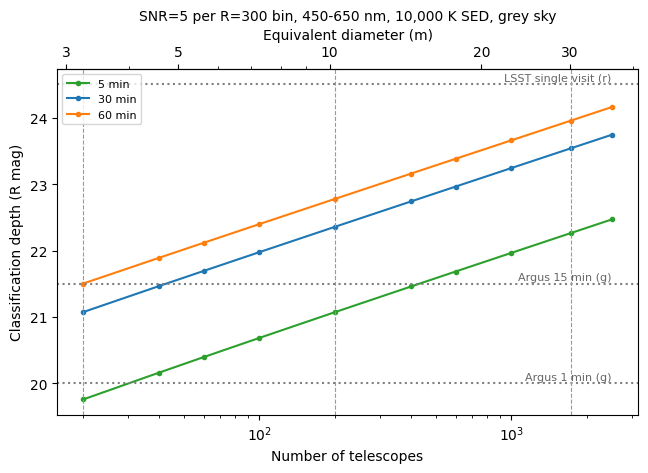

In [6]:
WINDOW = (450, 650); R_BIN = 300; SNR_CLASS = 5
snr_resel_class = SNR_CLASS / np.sqrt(1800 / R_BIN)
sn_like = Source.blackbody(10000, 0, "R")
def bench(n):
    return LFASTETC("bench_r1800", telescope=tel(n), wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
REFS = {"Argus 1 min (g)": 20.0, "Argus 15 min (g)": 21.5, "LSST single visit (r)": 24.5}
fig, ax = plt.subplots(figsize=(7.5, 4.5))
depth = {}
for exp, color in ((300, "C2"), (1800, "C0"), (3600, "C1")):
    d = np.array([bench(int(n)).limiting_magnitude(sn_like, exp, snr_resel_class, wavelength=WINDOW) for n in NS])
    depth[exp] = dict(zip(NS, d))
    ax.plot(NS, d, marker="o", ms=3, color=color, label=f"{exp / 60:.0f} min")
for txt, mag in REFS.items():
    ax.axhline(mag, color="0.5", ls=":"); ax.text(NS[-1], mag + 0.05, txt, fontsize=8, color="0.4", ha="right")
ax.set_ylabel("Classification depth (R mag)")
ax.set_title("SNR=5 per R=300 bin, 450-650 nm, 10,000 K SED, grey sky"); ax.legend(loc="upper left")
mark_scales(ax)
pd.DataFrame({f"N={n}": {exp // 60: depth[exp][n] for exp in depth} for n in SCALES}).rename_axis("exposure (min)").round(1)
# 86 arrays reach R ~ 24.0 in 60 min, within ~0.5 mag of the LSST single-visit depth.

### 5.5 — The bright end

With one combiner input per array, the light per detector pixel is set by a single array and does
not grow with the number of arrays, so the bright limit is the same at 20, 200 and 1720 telescopes.
Tabulate the brightest star for which a 1 s (Bench) or 8 s (CSHELL, Fowler minimum) read stays below
80% of full well, for the three scales. What would an idealised single combiner do instead?

In [7]:
bright = {}
for preset, band, teff, kw, tmin in (("bench_r1800", "V", 5800, {}, 1.0), ("cshell_r18000", "H", 4500, dict(wavelength_min_nm=cs_lo, wavelength_max_nm=cs_hi), 8.0)):
    row = {}
    for n in SCALES:
        e = LFASTETC(preset, telescope=tel(n), **kw)
        mags = np.arange(-2, 14, 0.1)
        peak = np.array([np.nanmax(e.snr(Source.blackbody(teff, m, band), tmin).peak_e_per_pixel) for m in mags])
        row[f"N={n}"] = f"{band} > {mags[peak < 0.8 * e.instrument.full_well].min():.1f}"
    bright[f"{preset} ({tmin:.0f} s read)"] = row
pd.DataFrame(bright).T.rename_axis("brightest unsaturated star")
# A single combiner would saturate N/20 times sooner. A brighter star has to be attenuated:
# fewer telescopes per array, or a neutral-density filter.

,N=20,N=200,N=1720
brightest unsaturated star,,,
bench_r1800 (1 s read),V > 4.1,V > 4.1,V > 4.1
cshell_r18000 (8 s read),H > -0.6,H > -0.6,H > -0.6


> 🤖 **Ask Jupyter AI:** *Add the kilonova horizon: for an AT2017gfo-like kilonova at 0.5, 1, 2 and 3 days after merger, plot the distance at which it can still be classified in 30 minutes against N, with the LIGO O4 (150-170 Mpc) and O5 (225-295 Mpc) binary-neutron-star ranges shaded. At what array size does the 1-day horizon pass the O5 range?*

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/lfast-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*